In [1]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [ ]:
from datasets import load_from_disk
from transformers import AutoTokenizer

base_path = "/content/drive/MyDrive/NLP_Preprocessed"

# Load datasets
train_data = load_from_disk(f"{base_path}/t5_tokenized_train")
val_data = load_from_disk(f"{base_path}/t5_tokenized_val")
test_data = load_from_disk(f"{base_path}/t5_tokenized_test")

# Load tokenizer
tokenizer = AutoTokenizer.from_pretrained(f"{base_path}/t5_tokenizer")

In [ ]:
from transformers import (
    T5ForConditionalGeneration,
    Seq2SeqTrainer,
    Seq2SeqTrainingArguments,
    DataCollatorForSeq2Seq
)

In [ ]:
pip install evaluate

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 8.9 MB/s eta 0:00:00


In [ ]:
pip install sacrebleu

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 51.8/51.8 kB 4.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 104.1/104.1 kB 8.0 MB/s eta 0:00:00


In [ ]:
import evaluate
import numpy as np
import torch
import logging
from datasets import load_metric

# Configure logging
#logging.basicConfig(level = logging.INFO, format='%(asctime)s - %(levelname)s - %(message)s')

torch.cuda.empty_cache()
model = T5ForConditionalGeneration.from_pretrained("t5-small")

training_args = Seq2SeqTrainingArguments(
    output_dir = "/content/drive/MyDrive/NLP_Preprocessed/t5_results",
    eval_strategy = "epoch",
    save_strategy="epoch",
    learning_rate = 5e-5,
    per_device_train_batch_size = 4,
    per_device_eval_batch_size = 4,
    num_train_epochs = 5,
    weight_decay = 0.01,
    save_total_limit = 1,
    report_to = "none",
    predict_with_generate = True,  # important to generate prediction
    fp16 = True,
    load_best_model_at_end=True,
    metric_for_best_model="accuracy",
    greater_is_better=True
)

#accuracy_metric = evaluate.load("accuracy")

data_collator = DataCollatorForSeq2Seq(tokenizer, model=model)

def compute_metrics(eval_pred):
    predictions, labels = eval_pred

    # In case that predictions is a tuple
    if isinstance(predictions, tuple):
        predictions = predictions[0]

    # Replace -100 in predictions and labels
    predictions = np.where(predictions != -100, predictions, tokenizer.pad_token_id)
    labels = np.where(labels != -100, labels, tokenizer.pad_token_id)

    # Logging for sanity check
    #logging.info(f"Sample cleaned predictions: {predictions[:2]}")
    #logging.info(f"Sample cleaned labels: {labels[:2]}")

    # Decode
    #try:
    decoded_preds = tokenizer.batch_decode(predictions, skip_special_tokens=True)
    decoded_labels = tokenizer.batch_decode(labels, skip_special_tokens=True)

    # Prevent error
    #except TypeError as e:
        #logging.error(f"TypeError during batch_decode: {e}")
        #logging.error(f"Problematic predictions: {predictions}")
        #logging.error(f"Problematic labels: {labels}")
        #raise

    # Strip text
    decoded_preds = [pred.strip() for pred in decoded_preds]
    decoded_labels = [label.strip() for label in decoded_labels]

    bleu = load_metric("sacrebleu")
    result = bleu.compute(predictions = decoded_preds, references = [[label] for label in decoded_labels])

    # Exact match
    matches = [int(pred == label) for pred, label in zip(decoded_preds, decoded_labels)]

    return {
        "bleu": result["score"],
        "accuracy": sum(matches) / len(matches)
    }

trainer = Seq2SeqTrainer(
    model = model,
    args = training_args,
    train_dataset = train_data,
    eval_dataset = val_data,
    tokenizer = tokenizer,
    data_collator=data_collator,
    compute_metrics = compute_metrics,
)

# Train model
trainer.train()

torch.cuda.empty_cache()

/tmp/ipython-input-22-4138474538.py:77: FutureWarning: `tokenizer` is deprecated and will be removed in version 5.0.0 for `Seq2SeqTrainer.__init__`. Use `processing_class` instead.
  trainer = Seq2SeqTrainer(


Epoch,Training Loss,Validation Loss,Bleu,Accuracy
1,0.051700,0.044428,52.366577,0.207758
2,0.044700,0.038715,54.499211,0.284272
3,0.041700,0.036190,54.968409,0.328640
4,0.036300,0.034886,55.401881,0.347768
5,0.036500,0.034571,55.125003,0.354410


There were missing keys in the checkpoint model loaded: ['encoder.embed_tokens.weight', 'decoder.embed_tokens.weight', 'lm_head.weight'].


In [ ]:
train_results = trainer.predict(train_data)

print("Train Accuracy:", train_results.metrics["test_accuracy"])

Train Accuracy: 0.38992958682077855


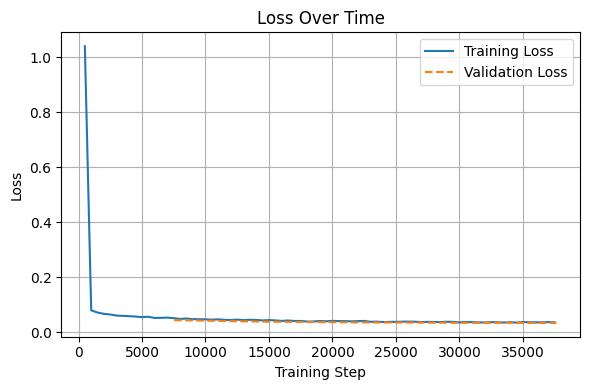

In [ ]:
import matplotlib.pyplot as plt

logs = trainer.state.log_history

steps = []
train_steps = []
train_loss = []
eval_steps = []
eval_loss = []

for entry in logs:
  if 'loss' in entry and 'step' in entry:
    steps.append(entry['step'])
    train_loss.append(entry['loss'])

  if 'eval_loss' in entry:
    eval_loss.append(entry['eval_loss'])

# Plot Training & Validation Loss
plt.figure(figsize=(6, 4))
plt.plot(steps, train_loss, label='Training Loss')
if eval_loss:
  eval_steps = [entry['step'] for entry in logs if 'eval_loss' in entry]
  plt.plot(eval_steps, eval_loss, label = 'Validation Loss', linestyle = '--')

plt.xlabel("Training Step")
plt.ylabel("Loss")
plt.title("Loss Over Time")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
model.save_pretrained("/content/drive/MyDrive/NLP_Preprocessed/t5_grammar_spelling_model")
tokenizer.save_pretrained("/content/drive/MyDrive/NLP_Preprocessed/t5_grammar_spelling_model")

('/content/drive/MyDrive/NLP_Preprocessed/t5_grammar_spelling_model/tokenizer_config.json',
 '/content/drive/MyDrive/NLP_Preprocessed/t5_grammar_spelling_model/special_tokens_map.json',
 '/content/drive/MyDrive/NLP_Preprocessed/t5_grammar_spelling_model/tokenizer.json')

In [ ]:
from transformers import (
    T5ForConditionalGeneration,
    Seq2SeqTrainer,
    Seq2SeqTrainingArguments,
    DataCollatorForSeq2Seq
)

from datasets import load_from_disk
import evaluate
import numpy as np
import torch
import logging

torch.cuda.empty_cache()
model = T5ForConditionalGeneration.from_pretrained("/content/drive/MyDrive/NLP_Preprocessed/t5_grammar_spelling_model")
tokenizer = AutoTokenizer.from_pretrained("/content/drive/MyDrive/NLP_Preprocessed/t5_grammar_spelling_model")

training_args = Seq2SeqTrainingArguments(
    output_dir = "/content/drive/MyDrive/NLP_Preprocessed/t5_results",
    eval_strategy = "epoch",
    learning_rate = 5e-5,
    per_device_train_batch_size = 4,

    # Reduce the evaluation batch size for prediction to avoid OOM
    per_device_eval_batch_size = 2, # Reduced from 4 to 2
    num_train_epochs = 3,
    weight_decay = 0.01,
    save_total_limit = 1,
    report_to = "none",
    predict_with_generate=True,  # important to generate prediction
    fp16=True
)

data_collator = DataCollatorForSeq2Seq(tokenizer, model = model)

def compute_metrics(eval_pred):
    predictions, labels = eval_pred

    if isinstance(predictions, tuple):
        predictions = predictions[0]

    predictions = np.where(predictions != -100, predictions, tokenizer.pad_token_id)
    labels = np.where(labels != -100, labels, tokenizer.pad_token_id)

    # Decode
    decoded_preds = tokenizer.batch_decode(predictions, skip_special_tokens=True)
    decoded_labels = tokenizer.batch_decode(labels, skip_special_tokens=True)

    # Strip text
    decoded_preds = [pred.strip() for pred in decoded_preds]
    decoded_labels = [label.strip() for label in decoded_labels]

    # Exact match
    matches = [int(pred == label) for pred, label in zip(decoded_preds, decoded_labels)]
    return {"accuracy": sum(matches) / len(matches)}

trainer = Seq2SeqTrainer(
    model = model,
    args = training_args,
    train_dataset = train_data,
    eval_dataset = val_data,
    tokenizer = tokenizer,
    data_collator=data_collator,
    compute_metrics = compute_metrics
)

/tmp/ipython-input-15-643429012.py:57: FutureWarning: `tokenizer` is deprecated and will be removed in version 5.0.0 for `Seq2SeqTrainer.__init__`. Use `processing_class` instead.
  trainer = Seq2SeqTrainer(


In [ ]:
# Run prediction on test data
test_results = trainer.predict(test_data)

# Compute test accuracy
print("Test Accuracy:", test_results.metrics["test_accuracy"])

print(test_results.metrics)

Test Accuracy: 0.34883103081827843
{'test_loss': 0.035090092569589615, 'test_model_preparation_time': 0.0139, 'test_accuracy': 0.34883103081827843, 'test_runtime': 256.6859, 'test_samples_per_second': 14.664, 'test_steps_per_second': 7.332}


In [ ]:
from evaluate import load
import numpy as np

# Compute BLEU

bleu = load("bleu")

preds_to_decode = np.where(test_results.predictions != -100, test_results.predictions, tokenizer.pad_token_id)
refs_to_decode = np.where(test_results.label_ids != -100, test_results.label_ids, tokenizer.pad_token_id)

# Detokenized predictions and references
preds = tokenizer.batch_decode(preds_to_decode, skip_special_tokens = True)
refs = tokenizer.batch_decode(refs_to_decode, skip_special_tokens = True)

# BLEU expects references as list of list (one or more references per sample)
refs = [[ref] for ref in refs]

# Compute BLEU
score = bleu.compute(predictions = preds, references = refs)
print("BLEU:", score["bleu"])

BLEU: 0.504375816578761


In [2]:
from transformers import AutoTokenizer, T5ForConditionalGeneration

# Load model
model_path = "/content/drive/MyDrive/NLP_Preprocessed/t5_grammar_spelling_model"
tokenizer = AutoTokenizer.from_pretrained(model_path)
model = T5ForConditionalGeneration.from_pretrained(model_path)

input_text = (
    "yesterday i was going to the libary but it was closed becaus of a holidy, "
    "so i went back home and wach a movi insted. the wether was also not so good."
)

# Tokenize and generate prediction
inputs = tokenizer([input_text], max_length=128, return_tensors="pt", truncation=True)
outputs = model.generate(**inputs, max_length=128, num_beams=4, early_stopping=True)

corrected_text = tokenizer.decode(outputs[0], skip_special_tokens=True)

print("Input Text: ", input_text)
print()
print("Corrected:", corrected_text)

Input Text:  yesterday i was going to the libary but it was closed becaus of a holidy, so i went back home and wach a movi insted. the wether was also not so good.

Corrected: Yesterday I was going to the libary but it was closed by a holidy, so I went back home and wach a movi insted.
